## 1. 导入依赖

先在当前 Python 环境安装 requirements.txt 中的依赖，再从上到下运行全部单元。重启内核后也需要重新顺序运行。


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

## 2. 读取数据并查看完整光谱

将 SourceGratingTrans.csv 放在笔记本所在目录，并以该目录作为工作目录。Wavelength 是波长（nm），dBm 是对数光功率。检查缺失值后观察完整光谱，确定目标谷的位置。数据来源：[巴斯大学公开数据仓库](https://researchdata.bath.ac.uk/1662/)，Smith 与 Mosley（2026），DOI：10.15125/BATH-01662，许可：CC BY 4.0。


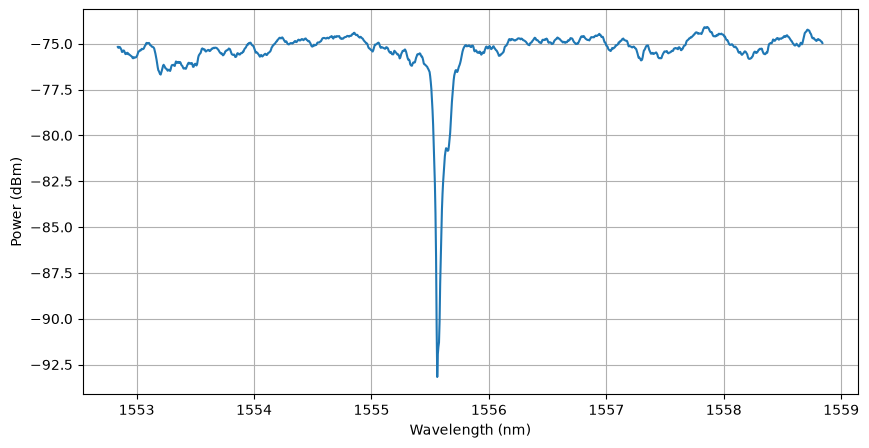

   Wavelength     dBm
0    1552.840 -75.177
1    1552.845 -75.226
2    1552.850 -75.194
3    1552.855 -75.178
4    1552.860 -75.202
Wavelength    0
dBm           0
dtype: int64
数据点数： 1201


In [43]:
data = pd.read_csv(r'SourceGratingTrans.csv')

# 将两列转换为 NumPy 数组，便于索引、计算和拟合。
wavelength = data['Wavelength'].to_numpy()
power_dbm = data['dBm'].to_numpy()

plt.figure(figsize=(10,5))
plt.plot(wavelength, power_dbm)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Power (dBm)')
plt.grid()
plt.show()

print(data.head())       # 查看前5行
print(data.isna().sum()) # 查看每列缺失值数量
print("数据点数：", len(data))

## 3. 截取目标谷附近的波段

本例选择 1555.2–1555.9 nm。分析其他光谱时，需要先观察全谱，再调整范围。波长和功率必须使用同一个筛选条件，保持逐点对应；改变区间可能影响拟合结果。


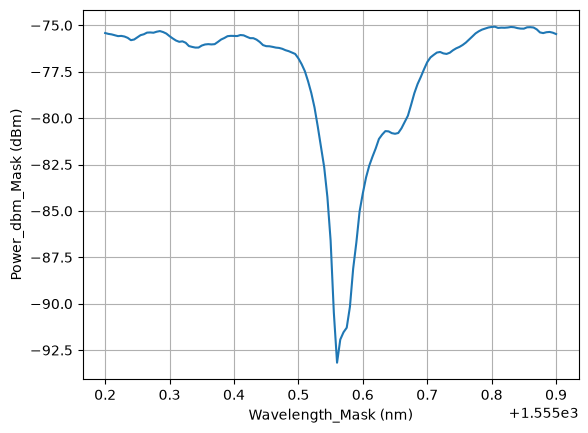

In [44]:
# & 表示两个条件同时成立；每个比较条件都需要括号。
mask = (wavelength >= 1555.2) & (wavelength <= 1555.9)
# 同一个 mask 同时用于两列，避免波长与功率错位。
wavelength_mask = wavelength[mask]
power_dbm_mask = power_dbm[mask]

plt.plot(wavelength_mask, power_dbm_mask)
plt.xlabel('Wavelength_Mask (nm)')
plt.ylabel('Power_dbm_Mask (dBm)')
plt.grid()
plt.show()

## 4. 用最低采样点估计中心

argmin 返回局部功率数组中最小值的索引，再用同一索引读取局部波长和功率。此结果受采样间隔与噪声影响，不是已知的真实中心。


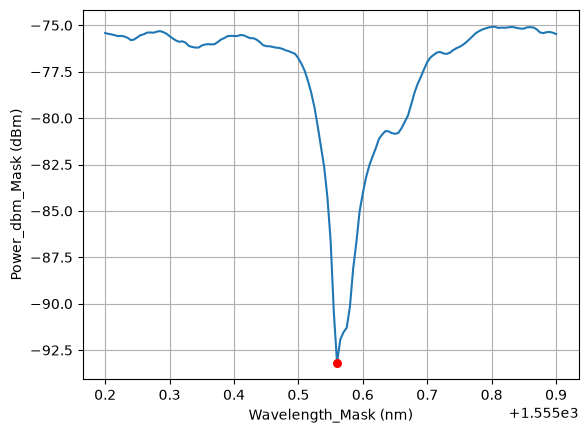

In [45]:
# 这里得到的是局部数组的索引，后续也要访问局部数组。
min_index = np.argmin(power_dbm_mask)
min_wavelength_mask = wavelength_mask[min_index]
min_power_dbm_mask = power_dbm_mask[min_index]

plt.plot(wavelength_mask, power_dbm_mask)
plt.scatter(min_wavelength_mask, min_power_dbm_mask,c = 'red',s = 30,zorder=10)
plt.xlabel('Wavelength_Mask (nm)')
plt.ylabel('Power_dbm_Mask (dBm)')
plt.grid()
plt.show()

## 5. 用高斯谷模型拟合

这是对 dBm 曲线的经验拟合，并非完整的 FBG 物理模型。模型参数依次为背景 b（dBm）、谷深 A（dB）、中心 c（nm）、宽度参数 w（nm）。w 不是半高全宽。初始猜测按同一顺序传入；当前代码未设置参数边界，需要检查拟合结果是否合理。实际谷形不对称，因此对称高斯模型可能存在系统性偏差。


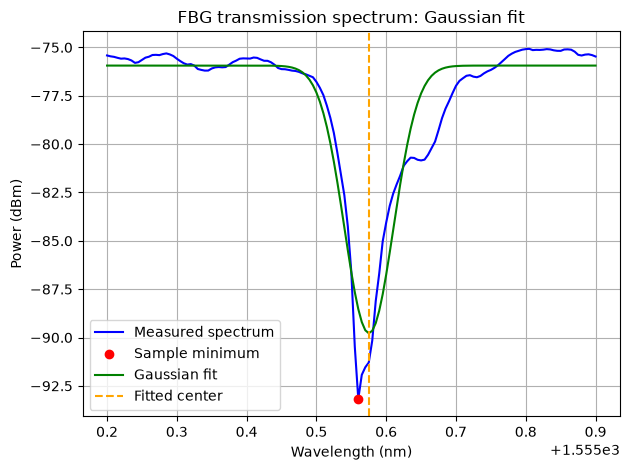

In [38]:
def gaussian_dip(wavelength, b,A,c,w):
    # 在 wavelength == c 时，模型值为 b - A。
    return b - A*np.exp(-((wavelength-c)/w)**2)

# p 的顺序为 [b, A, c, w]；cov 是参数协方差的估计矩阵。
# p0 中心采用最低点波长；初始宽度为 0.1 nm。
p,cov = curve_fit(gaussian_dip,wavelength_mask,power_dbm_mask,p0 = [-75,18,min_wavelength_mask,0.1])
# 使用全部四个拟合参数，在同一组局部波长上计算预测值。
y =gaussian_dip(wavelength_mask,p[0],p[1],p[2],p[3])

plt.plot(wavelength_mask, power_dbm_mask,
         color="blue", label="Measured spectrum")

plt.scatter(min_wavelength_mask, min_power_dbm_mask,
            color="red", zorder=5, label="Sample minimum")

plt.plot(wavelength_mask, y,
         color="green", label="Gaussian fit")

plt.axvline(p[2], color="orange", linestyle="--",
            label="Fitted center")

plt.xlabel("Wavelength (nm)")
plt.ylabel("Power (dBm)")
plt.title("FBG transmission spectrum: Gaussian fit")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

## 6. 计算残差与中心差值

残差定义为测量值减拟合值，两个 dBm 值相减得到的差值单位为 dB。中心差值取绝对值，并由 nm 换算为 pm。没有精确真值，因此方法间差异不能称为定位误差，也不能据此判断哪种方法更准确。输出小数位不代表测量精度。


In [28]:
# 两个数组在相同波长位置逐点相减。
residual =power_dbm_mask - y
center_fit = p[2]
# 1 nm = 1000 pm；这里是方法间差异，不是真值误差。
difference_pm = np.abs(center_fit - min_wavelength_mask)*1000

print(f"最低点法中心：{min_wavelength_mask:.6f} nm")
print(f"拟合法中心：{center_fit:.6f} nm")
print(f"两种方法的差值：{difference_pm:.3f} pm")

最低点法中心：1555.560000 nm
拟合法中心：1555.575272 nm
两种方法的差值：15.272 pm


## 7. 检查残差图

零线表示测量值与拟合值相等；正残差表示测量值较高，负残差表示测量值较低。连续波峰、波谷等规律说明模型未充分描述数据。本例谷底和右侧肩部的偏差应纳入结论，不能仅以拟合成功作为模型适合的依据。


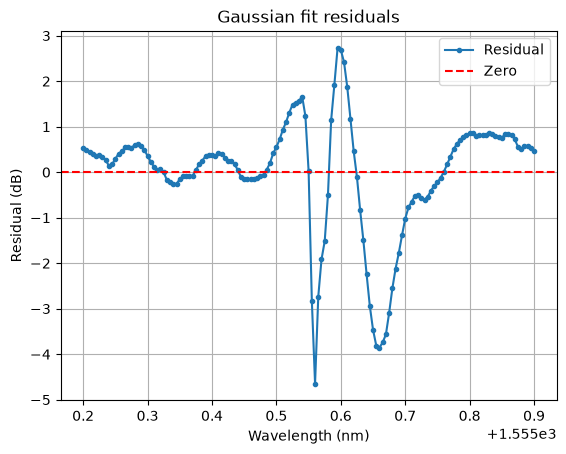

In [34]:
plt.plot(wavelength_mask,residual, '.-', label='Residual')
plt.axhline(0, color='red', linestyle='--', label='Zero')
plt.xlabel('Wavelength (nm)')
plt.ylabel('Residual (dB)')
plt.title('Gaussian fit residuals')
plt.legend()
plt.grid()
plt.show()